# 5.2. Багатошаровий перцептрон для MNIST

Модель бачить 784 пікселі як вектор. 100 епох і batch_size=200 — за умовою. Контроль перенавчання: окрема validation-вибірка та збереження найкращих ваг. Test не використовуємо для налаштування.

In [1]:
from pathlib import Path  # Підключаємо бібліотеку або інструмент: pathlib Path.
import json, time  # Підключаємо бібліотеку або інструмент: json, time.
import numpy as np  # Підключаємо бібліотеку або інструмент: numpy as np.
import matplotlib.pyplot as plt  # Підключаємо бібліотеку або інструмент: matplotlib.pyplot as plt.
import tensorflow as tf  # Підключаємо бібліотеку або інструмент: tensorflow as tf.
from tensorflow import keras  # Підключаємо бібліотеку або інструмент: tensorflow keras.
from sklearn.model_selection import train_test_split, StratifiedKFold  # Підключаємо бібліотеку або інструмент: sklearn.model_selection train_test_split, StratifiedKFold.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # Підключаємо бібліотеку або інструмент: sklearn.metrics classification_report, confusion_matrix, ConfusionMatrixDisplay.

# У Colab файли створюються в поточній папці; у репозиторії — в його корені.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()  # Обчислюємо та зберігаємо значення у змінній ROOT.
for folder in ('models', 'results'):  # Повторюємо вкладені дії для кожного елемента циклу.
    (ROOT/folder).mkdir(exist_ok=True)  # Обчислюємо та зберігаємо значення у змінній (ROOT/folder).mkdir(exist_ok.
keras.utils.set_random_seed(42)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
print('TensorFlow:', tf.__version__, 'Keras:', keras.__version__)  # Виводимо поточний результат або перевірочні значення.
print('Пристрої:', tf.config.list_physical_devices())  # Виводимо поточний результат або перевірочні значення.

TensorFlow: 2.21.0 Keras: 3.15.1


Пристрої: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
(raw_train, labels_train), (raw_test, labels_test) = keras.datasets.mnist.load_data()  # Завантажуємо набір MNIST із зображеннями та правильними мітками.
# Однаковий стратифікований поділ для чесного порівняння всіх архітектур.
indices_train, indices_val = train_test_split(  # Створюємо окремі тренувальну й перевірочну частини даних.
    np.arange(len(raw_train)), test_size=10000, stratify=labels_train, random_state=42)  # Обчислюємо та зберігаємо значення у змінній np.arange(len(raw_train)), test_size.
print('Train:', len(indices_train), 'validation:', len(indices_val), 'test:', len(raw_test))  # Виводимо поточний результат або перевірочні значення.

Train: 50000 validation: 10000 test: 10000


## 1. Зображення та підготовка
Перші чотири картинки показуємо лише для ознайомлення. Для розпізнавання нижче беремо інші, наперед зафіксовані індекси.

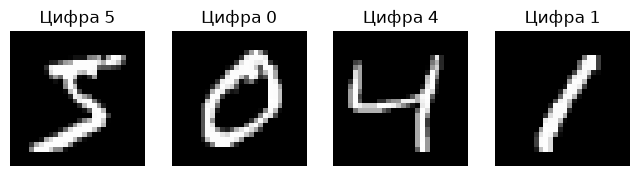

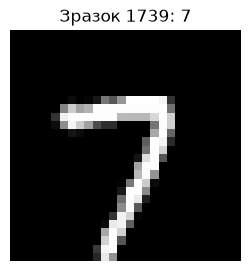

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2))  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
for i, ax in enumerate(axes):  # Повторюємо вкладені дії для кожного елемента циклу.
    ax.imshow(raw_train[i], cmap='gray'); ax.set_title(f'Цифра {labels_train[i]}'); ax.axis('off')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
plt.figure(figsize=(3,3)); plt.imshow(raw_train[1739], cmap='gray'); plt.title(f'Зразок 1739: {labels_train[1739]}'); plt.axis('off'); plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
# Float32 та ділення на 255: ознаки від 0 до 1. One-hot: один із десяти класів.
mlp_all = raw_train.reshape(-1, 784).astype('float32') / 255.0  # Змінюємо форму масиву під формат, якого очікує модель.
mlp_test = raw_test.reshape(-1, 784).astype('float32') / 255.0  # Змінюємо форму масиву під формат, якого очікує модель.
mlp_targets = keras.utils.to_categorical(labels_train, 10)  # Перетворюємо мітки цифр на one-hot вектори з десяти класів.
mlp_test_targets = keras.utils.to_categorical(labels_test, 10)  # Перетворюємо мітки цифр на one-hot вектори з десяти класів.

## 2. Архітектура й навчання
784 → 784 ReLU → 10 Softmax. Adam мінімізує categorical_crossentropy; accuracy — частка правильних відповідей.

In [4]:
mlp_model = keras.Sequential([  # Обчислюємо та зберігаємо значення у змінній mlp_model.
    keras.layers.Input((784,)),  # Задаємо форму вхідних даних для однієї цифри.
    keras.layers.Dense(784, activation='relu'),  # Додаємо повнозв’язний шар; останній шар формує оцінки десяти цифр.
    keras.layers.Dense(10, activation='softmax')  # Додаємо повнозв’язний шар; останній шар формує оцінки десяти цифр.
], name='mnist_mlp')  # Обчислюємо та зберігаємо значення у змінній ], name.
mlp_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])  # Обираємо функцію втрат для міток у форматі one-hot.
mlp_model.summary()  # Виконуємо цей крок обчислення для поточного досліду.
mlp_history = mlp_model.fit(mlp_all[indices_train], mlp_targets[indices_train],  # Навчаємо модель на тренувальних даних і стежимо за перевірочною вибіркою.
    validation_data=(mlp_all[indices_val], mlp_targets[indices_val]),  # Обчислюємо та зберігаємо значення у змінній validation_data.
    epochs=100, batch_size=200, verbose=2,  # Обчислюємо та зберігаємо значення у змінній epochs.
    callbacks=[keras.callbacks.ModelCheckpoint(str(ROOT/'models/mlp_best.keras'), monitor='val_loss', save_best_only=True),  # Зберігаємо ваги моделі з найкращою перевірочною втратою.
               keras.callbacks.CSVLogger(str(ROOT/'results/mlp_epochs.csv'))])  # Записуємо показники кожної епохи у CSV-файл.

Model: "mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

...

250/250 - 2s - 8ms/step - accuracy: 1.0000 - loss: 7.1764e-08 - val_accuracy: 0.9830 - val_loss: 0.1441


Epoch 99/100


250/250 - 2s - 7ms/step - accuracy: 1.0000 - loss: 6.6857e-08 - val_accuracy: 0.9829 - val_loss: 0.1448


Epoch 100/100


250/250 - 2s - 7ms/step - accuracy: 1.0000 - loss: 6.2320e-08 - val_accuracy: 0.9829 - val_loss: 0.1453


In [4]:
def plot_history(history, title, filename):  # Оголошуємо функцію; її назва показує, яку дію вона виконує.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
    for ax, metric in zip(axes, ('accuracy', 'loss')):  # Повторюємо вкладені дії для кожного елемента циклу.
        ax.plot(np.arange(1, len(history[metric])+1), history[metric], label='train')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.plot(np.arange(1, len(history[metric])+1), history['val_'+metric], label='validation')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.set(xlabel='Епоха', ylabel=metric, title=title)  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
        ax.legend(); ax.grid(alpha=.25)  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
    fig.tight_layout(); fig.savefig(ROOT/'results'/filename, dpi=150); plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.

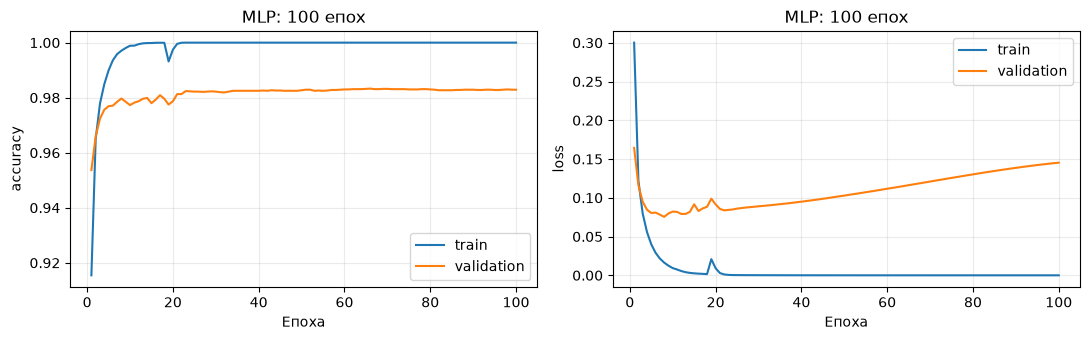

{'test_accuracy': 0.9787999987602234, 'test_loss': 0.07316034287214279, 'test_error': 0.02120000123977661, 'best_epoch': 8, 'epochs': 100}


In [6]:
plot_history(mlp_history.history, 'MLP: 100 епох', 'mlp_learning.png')  # Виконуємо цей крок обчислення для поточного досліду.
mlp_best = keras.models.load_model(ROOT/'models/mlp_best.keras')  # Обчислюємо та зберігаємо значення у змінній mlp_best.
mlp_test_loss, mlp_test_accuracy = mlp_best.evaluate(mlp_test, mlp_test_targets, verbose=0)  # Оцінюємо готову модель на окремих даних.
mlp_result = dict(test_accuracy=float(mlp_test_accuracy), test_loss=float(mlp_test_loss),  # Обчислюємо та зберігаємо значення у змінній mlp_result.
    test_error=float(1-mlp_test_accuracy), best_epoch=int(np.argmin(mlp_history.history['val_loss'])+1), epochs=100)  # Знаходимо епоху з найменшою перевірочною втратою.
(ROOT/'results/mlp_summary.json').write_text(json.dumps(mlp_result, indent=2), encoding='utf-8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/mlp_summary.json').write_text(json.dumps(mlp_result, indent.
print(mlp_result)  # Виводимо поточний результат або перевірочні значення.

## 3. Розпізнавання десяти цифр
Фіксована вибірка по одній цифрі кожного класу з індексів ≥2000. Жоден зразок не використаний для вибору моделі. Зовнішні зображення для MLP і CNN порівнюються у ноутбуці 05.

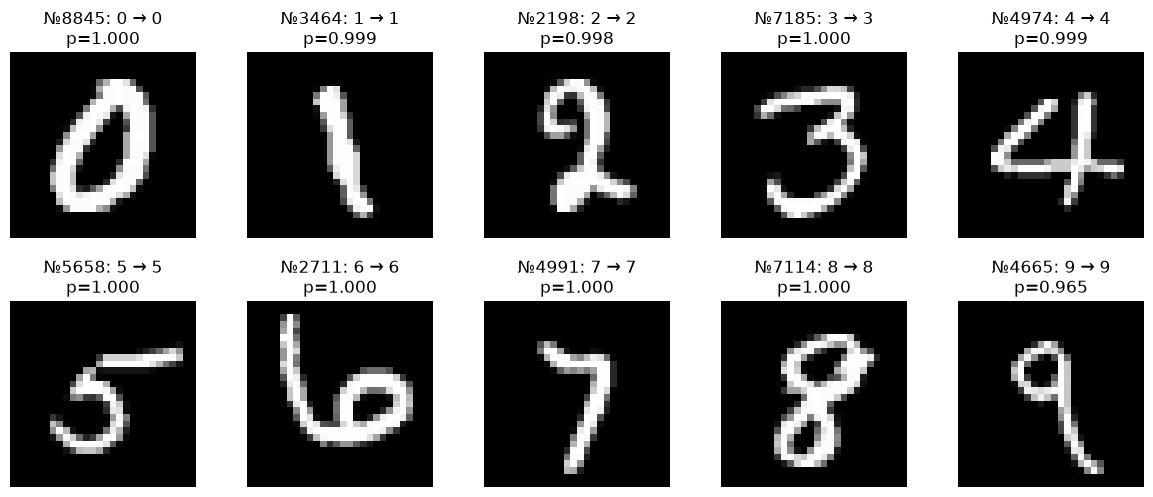

In [2]:
rng = np.random.default_rng(2026)  # Обчислюємо та зберігаємо значення у змінній rng.
sample_indices = np.array([rng.choice(np.flatnonzero((labels_test == digit) & (np.arange(len(labels_test)) >= 2000))) for digit in range(10)])  # Обчислюємо та зберігаємо значення у змінній sample_indices.
mlp_probs = mlp_best.predict(mlp_test[sample_indices], verbose=0)  # Обчислюємо ймовірності класів для вхідних зразків.
fig, axes = plt.subplots(2,5,figsize=(12,5))  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
for ax, idx, probs in zip(axes.flat, sample_indices, mlp_probs):  # Повторюємо вкладені дії для кожного елемента циклу.
    ax.imshow(raw_test[idx], cmap='gray'); ax.set_title(f'№{idx}: {labels_test[idx]} → {np.argmax(probs)}\np={np.max(probs):.3f}'); ax.axis('off')  # Налаштовуємо або показуємо графік для наочного аналізу результатів.
fig.tight_layout(h_pad=2.5); fig.savefig(ROOT/'results/mlp_10_mnist.png', dpi=150); plt.show()  # Налаштовуємо або показуємо графік для наочного аналізу результатів.

## 4. Спроба покращення перцептрона
Додаємо Dropout 20% та зменшуємо крок Adam удвічі. Дослід перевіряє, чи регуляризація зменшує перенавчання. Результат може бути кращим або гіршим; зберігаємо обидва. Вибір виконуємо за validation loss.

Epoch 1/50


250/250 - 3s - 13ms/step - accuracy: 0.8882 - loss: 0.4044 - val_accuracy: 0.9408 - val_loss: 0.2193


Epoch 2/50


250/250 - 2s - 9ms/step - accuracy: 0.9487 - loss: 0.1813 - val_accuracy: 0.9563 - val_loss: 0.1578


Epoch 3/50


...

250/250 - 1s - 5ms/step - accuracy: 0.9979 - loss: 0.0110 - val_accuracy: 0.9801 - val_loss: 0.0694


Epoch 20/50


250/250 - 1s - 5ms/step - accuracy: 0.9978 - loss: 0.0102 - val_accuracy: 0.9802 - val_loss: 0.0709


Epoch 21/50


250/250 - 1s - 5ms/step - accuracy: 0.9983 - loss: 0.0089 - val_accuracy: 0.9804 - val_loss: 0.0713


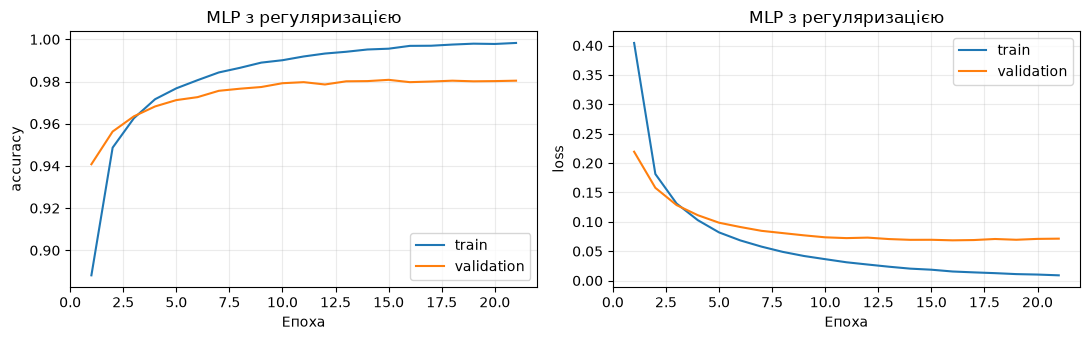

{'baseline_validation_loss': 0.0753939300775528, 'regularized_validation_loss': 0.06844072043895721, 'selected': 'mlp_regularized.keras', 'regularized_test_accuracy': 0.9811000227928162, 'regularized_test_loss': 0.06395617872476578, 'regularized_epochs': 21, 'learning_rate': 0.0005, 'dropout': 0.2}


In [7]:
# Другий дослід заздалегідь задано: та сама ширина 784, Dropout 0.2, Adam 0.0005.
# Порівняння і вибір — лише за validation loss.
import csv  # Підключаємо бібліотеку або інструмент: csv.
keras.utils.set_random_seed(43)  # Фіксуємо генератор випадкових чисел для відтворюваного досліду.
mlp_regularized = keras.Sequential([  # Обчислюємо та зберігаємо значення у змінній mlp_regularized.
    keras.layers.Input((784,)), keras.layers.Dense(784, activation='relu'),  # Задаємо форму вхідних даних для однієї цифри.
    keras.layers.Dropout(.2), keras.layers.Dense(10, activation='softmax')], name='mnist_mlp_regularized')  # Випадково вимикаємо частину нейронів під час навчання для регуляризації.
mlp_regularized.compile(optimizer=keras.optimizers.Adam(.0005), loss='categorical_crossentropy', metrics=['accuracy'])  # Обираємо функцію втрат для міток у форматі one-hot.
regularized_history = mlp_regularized.fit(mlp_all[indices_train], mlp_targets[indices_train],  # Навчаємо модель на тренувальних даних і стежимо за перевірочною вибіркою.
    validation_data=(mlp_all[indices_val], mlp_targets[indices_val]), epochs=50, batch_size=200, verbose=2,  # Обчислюємо та зберігаємо значення у змінній validation_data.
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),  # Зупиняємо навчання, якщо перевірочна втрата перестала покращуватися.
               keras.callbacks.ModelCheckpoint(str(ROOT/'models/mlp_regularized.keras'), monitor='val_loss', save_best_only=True),  # Зберігаємо ваги моделі з найкращою перевірочною втратою.
               keras.callbacks.CSVLogger(str(ROOT/'results/mlp_regularized_epochs.csv'))])  # Записуємо показники кожної епохи у CSV-файл.
plot_history(regularized_history.history, 'MLP з регуляризацією', 'mlp_regularized_learning.png')  # Виконуємо цей крок обчислення для поточного досліду.
with (ROOT/'results/mlp_epochs.csv').open() as f:  # Безпечно відкриваємо ресурс і закриємо його після блоку.
    baseline_val_loss = min(float(row['val_loss']) for row in csv.DictReader(f))  # Знаходимо епоху з найменшою перевірочною втратою.
improved_val_loss = min(regularized_history.history['val_loss'])  # Знаходимо епоху з найменшою перевірочною втратою.
selected_mlp_path = 'mlp_regularized.keras' if improved_val_loss < baseline_val_loss else 'mlp_best.keras'  # Обчислюємо та зберігаємо значення у змінній selected_mlp_path.
mlp_selected = keras.models.load_model(ROOT/'models'/selected_mlp_path)  # Обчислюємо та зберігаємо значення у змінній mlp_selected.
mlp_selected.save(ROOT/'models/mlp_selected.keras')  # Зберігаємо навчену модель або результат на диск.
reg_loss, reg_accuracy = mlp_regularized.evaluate(mlp_test, mlp_test_targets, verbose=0)  # Оцінюємо готову модель на окремих даних.
improvement_result = dict(baseline_validation_loss=baseline_val_loss,  # Обчислюємо та зберігаємо значення у змінній improvement_result.
    regularized_validation_loss=float(improved_val_loss), selected=selected_mlp_path,  # Обчислюємо та зберігаємо значення у змінній regularized_validation_loss.
    regularized_test_accuracy=float(reg_accuracy), regularized_test_loss=float(reg_loss),  # Обчислюємо та зберігаємо значення у змінній regularized_test_accuracy.
    regularized_epochs=len(regularized_history.epoch), learning_rate=.0005, dropout=.2)  # Обчислюємо та зберігаємо значення у змінній regularized_epochs.
(ROOT/'results/mlp_improvement.json').write_text(json.dumps(improvement_result, indent=2), encoding='utf8')  # Обчислюємо та зберігаємо значення у змінній (ROOT/'results/mlp_improvement.json').write_text(json.dumps(improvement_result, indent.
print(improvement_result)  # Виводимо поточний результат або перевірочні значення.

## Висновок
Порівнюємо train і validation на графіках. Зростання validation loss за малої train loss свідчить про перенавчання. У файлі mlp_best.keras збережена епоха з мінімальною validation loss, а не автоматично остання епоха. Значення виведені фактичним виконанням, не задані вручну.